# code_042 · Distributions, scale and support

**Book:** section 9.1. A self-contained exploration laboratory using invented building, load and sensor records. Prerequisites: arrays/tables and Chapter 8's case, timing and schema contracts. Restart and run all cells; all imports, helpers and generated inputs are here. Ordinary execution needs no files, network, keys, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_09_GUIDE.md), [execution evidence](../CHAPTER_09_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_042).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow one minute to run and 30–60 minutes to interpret. These scoped concept experiments disclose data/task controls rather than claim exhaustive estimator API coverage. Plots and construction identities are exploratory diagnostics, not independent predictive evidence. Only the hypothesis laboratory fits competing predictors, selects on development buildings and opens a protected final set after freezing its rule. All evidence is synthetic, with no structural-safety, population-calibration or causal claim.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=942;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 942


<a id="support"></a>
## Inspect a variable before transforming it

Generate positive member loads in kN for 240 steel and 160 concrete records. Steel follows lognormal(log(35),.35), concrete lognormal(log(70),.45). Three deliberately zero values denote recorded unloaded operation, not missingness. Add one separately flagged plausible high-load fixture 250 kN, a unit-error fixture storing 50,000 N as though kN, and a negative -3 kN whose meaning needs source review. Loads here are nonnegative magnitudes; signed force in a different task could legitimately be negative. Their truth is known only because the author constructs the fixtures.

Keep raw values, source units and review flags. Do not trim values simply because a boxplot or z score calls them unusual. Structural zeros differ from placeholders. An unobserved third material category remains in the declared schema but has no observations. No predictive model is fitted and no final-test distribution is inspected.


In [2]:
material=np.array(['steel']*240+['concrete']*160);load=np.r_[rng.lognormal(np.log(35),.35,240),rng.lognormal(np.log(70),.45,160)];load[[0,7,250]]=0
raw=pd.DataFrame({'record_id':np.arange(403),'material':np.r_[material,['steel','steel','concrete']],'stored_load':np.r_[load,250.,50000.,-3.],'source_unit':['kN']*401+['N','kN']})
raw['review']=np.concatenate([np.full(400,'ordinary'),['plausible_extreme','unit_mismatch','negative_magnitude']])
assert raw.record_id.is_unique and len(raw)==403 and (raw.stored_load==0).sum()==3
canonical=raw.stored_load.to_numpy().copy();canonical[raw.source_unit=='N']/=1000
assert canonical[401]==50 and raw.stored_load.iloc[401]==50000
eligible=(canonical>=0)&(raw.review!='negative_magnitude').to_numpy();clean=raw.assign(load_kN=canonical).loc[eligible].copy()
assert len(clean)==402 and clean.loc[clean.record_id==400,'load_kN'].iloc[0]==250
assert set(clean.source_unit)=={'N','kN'}
RESULTS.update({'raw_rows':len(raw),'reviewed_rows':len(clean),'genuine_zeros':3,'raw_max_as_if_kN':float(raw.stored_load.max()),'converted_unit_fixture_kN':float(canonical[401]),'unresolved_negative_records':1,'observed_max_kN':float(clean.load_kN.max())})


<a id="distributions"></a>
## Compare pooled and conditional distributions on the same scale

Common bins let bar locations mean the same thing across panels. Counts and fractions answer different questions when subgroup sizes differ. Show the overall distribution and each material, retaining zeros and the explicit high-load fixture. The display is a support audit, not a test that either material causes different load. Material and service conditions were bundled deliberately in this generator.


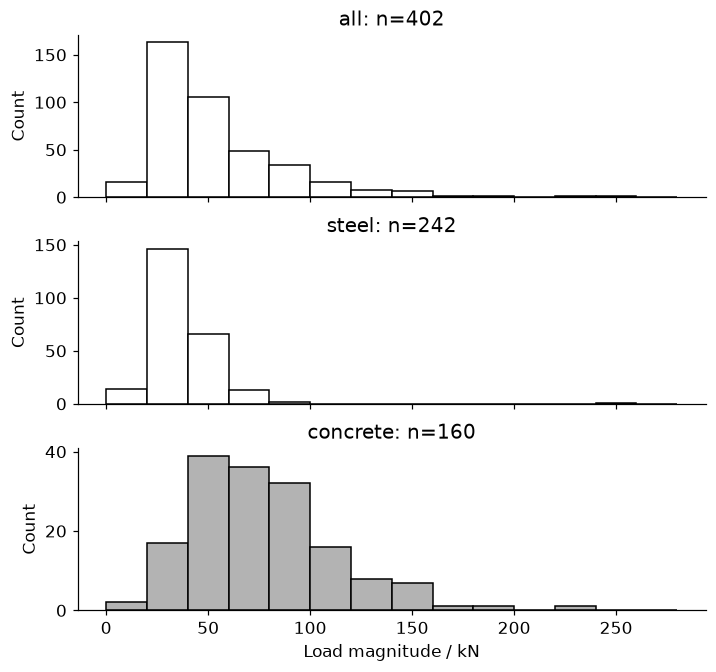

In [3]:
bins=np.arange(0,np.ceil(clean.load_kN.max()/20)*20+21,20);fig,axes=plt.subplots(3,1,figsize=(6.4,6),sharex=True)
for ax,name in zip(axes,['all','steel','concrete']):
 values=clean.load_kN.to_numpy() if name=='all' else clean.loc[clean.material==name,'load_kN'].to_numpy()
 ax.hist(values,bins=bins,color='white' if name!='concrete' else '.7',edgecolor='black');ax.set(ylabel='Count',title=f'{name}: n={len(values)}');assert np.histogram(values,bins=bins)[0].sum()==len(values)
axes[-1].set(xlabel='Load magnitude / kN');plt.show()
quantiles={g:clean.loc[clean.material==g,'load_kN'].quantile([0,.5,.9,1]).tolist() for g in ['steel','concrete']}
RESULTS['material_quantiles_0_50_90_100_kN']=quantiles
assert max(clean.load_kN)<bins[-1]


<a id="transforms"></a>
## An ECDF and a justified logarithm answer different questions

An empirical CDF gives the fraction no greater than x, without histogram bins. Log(load/1 kN) is defined only for positive load; zeros must not silently disappear from the task. log1p(load/1 kN) is defined at zero but its reference scale is a choice that changes under unit conversions unless the physical reference is retained. This cell records the domains; it does not fit a model or choose a transformation by final error.


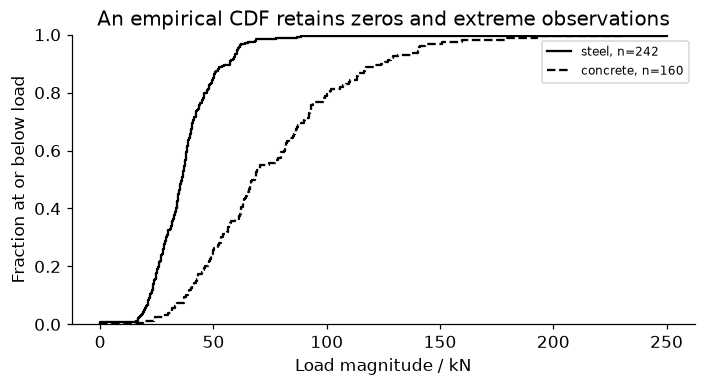

In [4]:
fig,ax=plt.subplots(figsize=(6.3,3.4))
for name,style in [('steel','-'),('concrete','--')]:
 v=clean.loc[clean.material==name,'load_kN'].to_numpy();ax.ecdf(v,label=f'{name}, n={len(v)}',ls=style,color='black')
ax.set(xlabel='Load magnitude / kN',ylabel='Fraction at or below load',title='An empirical CDF retains zeros and extreme observations');ax.legend(fontsize=8);plt.show()
pos=clean.load_kN>0;assert (~pos).sum()==3
log_positive=np.log(clean.loc[pos,'load_kN']/1.);assert np.isfinite(log_positive).all()
log1p_kN=np.log1p(clean.load_kN/1.);log1p_N=np.log1p((clean.load_kN*1000)/1000.);assert np.allclose(log1p_kN,log1p_N)
categories=pd.Categorical(clean.material,categories=['steel','concrete','timber']);counts=pd.Series(categories).value_counts(sort=False)
assert counts['timber']==0 and counts.sum()==402
RESULTS['declared_material_counts']={str(k):int(v) for k,v in counts.items()};RESULTS['ordinary_log_excluded_zero_rows']=int((~pos).sum())


<a id="exercises"></a>
## Exercises and hints

1. Replace common bins with unrelated subgroup bins; explain which visual comparisons become unreliable.
2. Increase the plausible extreme while preserving its provenance; propose source checks before deleting it.
3. Change the physical reference inside log1p and predict the effect on distances between small values.
4. Define a signed-force task in which negative values are valid, then change the schema and range checks.

**Hints:** observed support is not physically guaranteed support. Unknown categories may appear later. No sample maximum establishes a safe operating bound, and no outlier rule establishes recording error. See the official [ECDF interface](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ecdf.html); notebooks execute Matplotlib 3.11.0 while maintenance docs may advance.


In [5]:
summary={'example_id':'code_042','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['physical and observed support', 'common bins and subgroup distributions', 'zeros tails and unit-error review', 'empirical CDF without bin choices', 'category absence and logarithm domain'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["physical and observed support", "common bins and subgroup distributions", "zeros tails and unit-error review", "empirical CDF without bin choices", "category absence and logarithm domain"], "elapsed_seconds": 0.156, "example_id": "code_042", "hardware": "Darwin arm64 CPU", "results": {"converted_unit_fixture_kN": 50.0, "declared_material_counts": {"concrete": 160, "steel": 242, "timber": 0}, "genuine_zeros": 3, "material_quantiles_0_50_90_100_kN": {"concrete": [0.0, 67.63649852978091, 124.08078625483887, 230.1759787768046], "steel": [0.0, 36.0969461328602, 56.93042390118565, 250.0]}, "observed_max_kN": 250.0, "ordinary_log_excluded_zero_rows": 3, "raw_max_as_if_kN": 50000.0, "raw_rows": 403, "reviewed_rows": 402, "unresolved_negative_records": 1}, "seed": 942, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
